C:\Users\saniya maner\miniconda3\envs\tensorflow_env\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.3135 - loss: 1.9028
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.3875 - loss: 1.7129
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.4138 - loss: 1.6405
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.4340 - loss: 1.5847
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.4521 - loss: 1.5356
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4323 - loss: 1.5727
Test Accuracy: 43.230000138282776 %
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


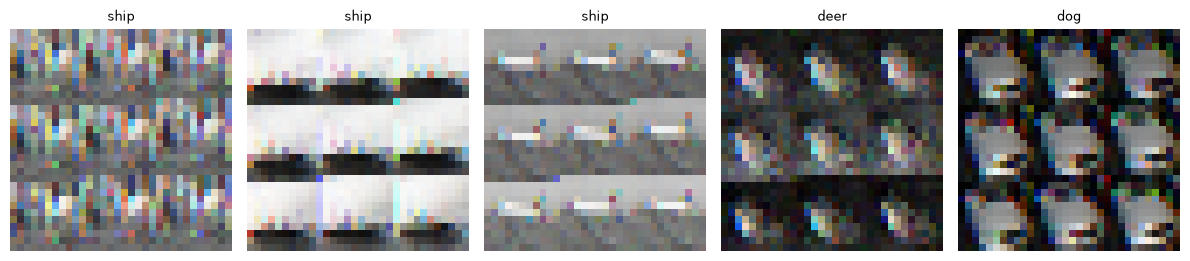

In [1]:

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense

# 2. Load dataset
data = pd.read_csv('cifar-10.csv')

# 3. Separate features and labels
X = data.drop('label', axis=1).values
y = data['label'].values

# 4. Normalize data
X = X / 255.0

# 5. Reshape images
X = X.reshape(-1, 32, 32, 3)

# 6. Split dataset into training and testing
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 7. Build FNN model
model = Sequential([
    Flatten(input_shape=(32, 32, 3)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

# 8. Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 9. Train model
model.fit(x_train, y_train, epochs=5, batch_size=64)

# 10. Test model
loss, accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", accuracy * 100, "%")

# 11. Predict images
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Display 5 predicted images clearly

predictions = model.predict(x_test[:5])

plt.figure(figsize=(12, 5))

for i in range(5):
    plt.subplot(1, 5, i + 1)

    plt.imshow(x_test[i], interpolation='nearest')

    predicted = np.argmax(predictions[i])

    plt.title(class_names[predicted], fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()